# Q1. Set Mismatch

You have a set of integers s, which originally contains all the numbers from 1 to n. Unfortunately, due to some error, one of the numbers in s got duplicated to another number in the set, which results in repetition of one number and loss of another number.

You are given an integer array nums representing the data status of this set after the error.

Find the number that occurs twice and the number that is missing and return them in the form of an array.

Основная идея: линейно проходить по массиву проверяя индекс и текущий элемент. При несовпадении  прерывать цикл и отдавать данные результаты. Соответственно возвращаем массив из двух значений: i-элемент и i+1

In [1]:
/*
class Solution {
    fun findErrorNums(nums: IntArray): IntArray {
        val result = intArrayOf(0,0)

        for (i in nums.indices){
            if (i+1 != nums[i])
            {
                result[0] = nums[i]
                result[1] = i+1
                break
            }
        }

        return result
    }
}
*/

Проверка:

In [5]:
val solution = Solution()

val example1 = solution.findErrorNums(intArrayOf(1,2,2,4))
println("${example1[0]}, ${example1[1]}")

val example2 = solution.findErrorNums(intArrayOf(1,1))
println("${example2[0]}, ${example2[1]}")

2, 3
1, 2


Итак, не было сказано, что массив отсортирован. Поэтому значения могут идти в случайном порядке. В таком случае можно идти следующими путями: проводить сортировку перед выполнением (что увеличит сложность), либо проходится по массиву, используя дополнительную структуру для хранения количества значений.

In [19]:
class Solution {
    fun findErrorNums(nums: IntArray): IntArray {

        val counter = IntArray(nums.size)

        for (i in nums){
           counter[i-1]+=1
        }

        return intArrayOf(counter.indexOf(2)+1, counter.indexOf(0)+1)
    }
}

In [20]:
val solution = Solution()

val example1 = solution.findErrorNums(intArrayOf(1,2,2,4))
println("${example1[0]}, ${example1[1]}")

val example2 = solution.findErrorNums(intArrayOf(1,1))
println("${example2[0]}, ${example2[1]}")

2, 3
1, 2


# Результат
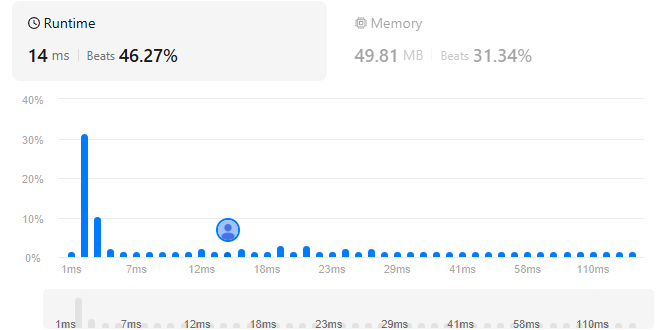

Попробуем с быстрой сортировкой:

In [21]:
class Solution {
    fun quickSort(arr: IntArray, left: Int = 0, right: Int = arr.size - 1): IntArray {
        var start = left
        var end = right
        val pivot = arr[(left + right) / 2]

        while (start <= end) {
            while (arr[start] < pivot) {
                start++
            }
            while (arr[end] > pivot) {
                end--
            }
            if (start <= end) {
                val temp = arr[start]
                arr[start] = arr[end]
                arr[end] = temp
                start++
                end--
            }
        }

        if (left < end) {
            quickSort(arr, left, end)
        }
        if (start < right) {
            quickSort(arr, start, right)
        }
        return arr
    }

    fun findErrorNums(nums: IntArray): IntArray {
        val result = intArrayOf(0,0)

        val sortedNums = quickSort(nums)

        for (i in sortedNums.indices){
            if (i+1 != sortedNums[i])
            {
                result[0] = sortedNums[i]
                result[1] = i+1
                break
            }
        }

        return result
    }
}

In [22]:
val solution = Solution()

val example1 = solution.findErrorNums(intArrayOf(1,2,2,4))
println("${example1[0]}, ${example1[1]}")

val example2 = solution.findErrorNums(intArrayOf(1,1))
println("${example2[0]}, ${example2[1]}")

2, 3
1, 2


Идея отвратительная. И нерабочая. Тогда улучшаем рабочую идею. Надо избавить от поиска индекса и вместо этого попытаться добиться операции за O(1)

In [27]:
class Solution {
    fun findErrorNums(nums: IntArray): IntArray {

        val result = intArrayOf(0,0)

        val counter = IntArray(nums.size)

        for (i in nums){
            counter[i-1]+=1
        }

        for (i in counter.indices)
        {
            if(counter[i]==0)
                result[1]=i+1
            if (counter[i]==2)
                result[0]=i+1
        }

        return result
    }
}

In [28]:
val solution = Solution()

val example1 = solution.findErrorNums(intArrayOf(1,2,2,4))
println("${example1[0]}, ${example1[1]}")

val example2 = solution.findErrorNums(intArrayOf(1,1))
println("${example2[0]}, ${example2[1]}")

2, 3
1, 2


Можно улучшить следующим образом: находить разность между суммами массива и последовательности. Тогда найдя повтор и прибавив разность мы найдём пропущенное значение

In [31]:
class Solution {
    fun findErrorNums(nums: IntArray): IntArray {
        val n = nums.size

        val counter = IntArray(n)
        val sum = n*(n+1)/2
        var dup = 0

        var curSum = 0


        for (i in nums){
            curSum+=i
            counter[i-1]+=1
            if(counter[i-1]==2)
                dup = i
        }

        return intArrayOf(dup,dup+(sum-curSum))
    }
}

In [32]:
val solution = Solution()

val example1 = solution.findErrorNums(intArrayOf(1,2,2,4))
println("${example1[0]}, ${example1[1]}")

val example2 = solution.findErrorNums(intArrayOf(1,1))
println("${example2[0]}, ${example2[1]}")

2, 3
1, 2


# Результат
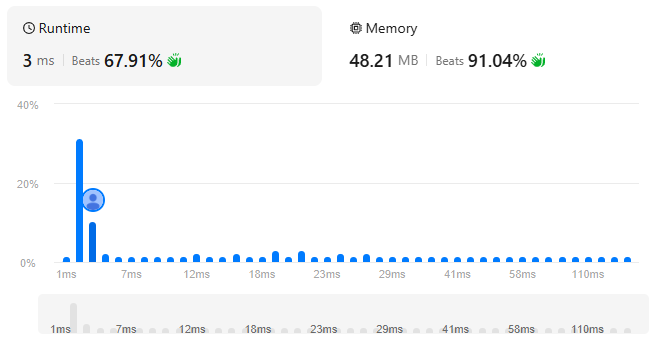

Значительное улучшение (хотя и несколько непредвиденное)

Иной способ: использовать set

In [33]:
class Solution {
    fun findErrorNums(nums: IntArray): IntArray {
        val n = nums.size

        val unique_nums = nums.toSet()

        val sum = n*(n+1)/2
        val unique_sum = unique_nums.sum()

        return intArrayOf(nums.sum() - unique_sum ,sum - unique_sum)
    }
}

In [34]:
val solution = Solution()

val example1 = solution.findErrorNums(intArrayOf(1,2,2,4))
println("${example1[0]}, ${example1[1]}")

val example2 = solution.findErrorNums(intArrayOf(1,1))
println("${example2[0]}, ${example2[1]}")

2, 3
1, 2


# Результат
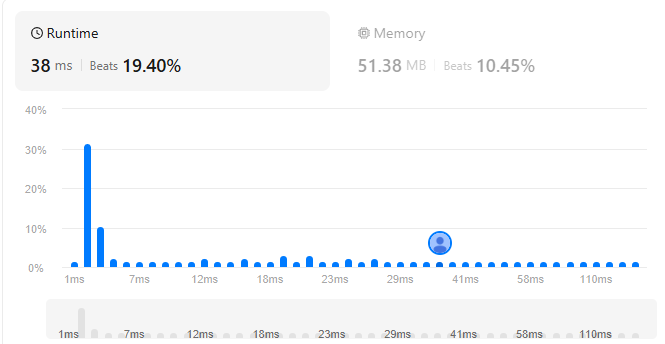